# Deploy-AD — PaDiM · PatchCore · EfficientAD on MVTec AD
**Kaggle T4 x2 · threshold-stable deployment evaluation**

All three baselines implement the same interface:

```python
model.fit(train_loader)                    # normal images only
scores, maps = model.score(loader)         # image scores + pixel anomaly maps
```

Everything downstream — metrics, thresholds, perturbations, tables — is **model-agnostic**,
so adding a fourth baseline later means writing one class, not touching the evaluation.

| Baseline | Idea | Role in the paper |
|---|---|---|
| PaDiM | per-position Gaussian + Mahalanobis | simple, fast to fit |
| PatchCore | coreset memory bank + k-NN | strong accuracy reference |
| EfficientAD | student–teacher + autoencoder | speed-first / deployment practicality |

> **Honest note on EfficientAD:** the official method distills its teacher (PDN) from
> WideResNet-101 on ImageNet, and those distilled weights are not downloadable inside a
> Kaggle no-internet session. This notebook implements the *architecture and training
> objective* faithfully but distills the teacher from a torchvision ResNet-18 at run time.
> Expect somewhat lower absolute AUROC than the published paper. For headline numbers in
> your manuscript, reproduce EfficientAD with `anomalib` in an internet-enabled session and
> state clearly which implementation produced which table.


In [1]:
# ── Cell 1: Imports & environment ────────────────────────────────
import os, io, json, time, random, gc, math
from pathlib import Path
from abc import ABC, abstractmethod

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights
from PIL import Image, ImageFilter, ImageEnhance
from sklearn.metrics import roc_auc_score, precision_recall_fscore_support
import matplotlib.pyplot as plt

print("Torch:", torch.__version__)
print("GPUs:", torch.cuda.device_count(),
      [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.24.3
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


Torch: 2.0.0
GPUs: 2 ['Tesla T4', 'Tesla T4']


In [2]:
# ── Cell 2: Config — freeze everything here ──────────────────────
class CFG:
    data_root_candidates = [
        "/kaggle/input/mvtec-ad",
        "/kaggle/input/datasets/ipythonx/mvtec-ad",
        "/kaggle/input/mvtec-ad/mvtec_anomaly_detection",
    ]
    out_dir = Path("/kaggle/working/results")

    # SHARED preprocessing — identical for all three models (critical for fair comparison)
    img_size    = 256
    center_crop = 256
    val_frac    = 0.2
    seed        = 42
    batch_size  = 16
    num_workers = 2

    # PaDiM
    padim_d = 100                 # random channel subset

    # PatchCore
    pc_coreset_ratio = 0.01       # 1% greedy coreset
    pc_n_neighbors   = 9
    pc_patch_pool    = 3          # local neighbourhood avg-pool

    # EfficientAD (reduced)
    ead_epochs   = 8              # raise to 20-30 for better numbers if time allows
    ead_lr       = 1e-4
    ead_channels = 384

    percentiles = [95.0, 97.5, 99.0]

    blur_sigmas        = [0.5, 1.0, 1.5]
    brightness_factors = [0.9, 1.1]
    jpeg_qualities     = [90, 70, 50]
    shift_pixels       = [4, 8]

def find_data_root():
    for c in CFG.data_root_candidates:
        p = Path(c)
        if p.exists():
            if (p / "bottle").exists():
                return p
            for sub in p.iterdir():
                if sub.is_dir() and (sub / "bottle").exists():
                    return sub
    base = Path("/kaggle/input")
    if base.exists():
        for hit in base.rglob("bottle/train/good"):
            return hit.parent.parent.parent
    raise FileNotFoundError("MVTec AD not found — run `!ls /kaggle/input` and update CFG.")

DATA_ROOT = find_data_root()
CATEGORIES = sorted([d.name for d in DATA_ROOT.iterdir()
                     if d.is_dir() and (d / "train" / "good").exists()])
print("Data root:", DATA_ROOT)
print(f"{len(CATEGORIES)} categories:", CATEGORIES)
assert len(CATEGORIES) == 15, "Expected 15 categories — check the dataset path."

TEXTURES = {"carpet", "grid", "leather", "tile", "wood"}   # for subgroup analysis

for sub in ["clean", "perturbed", "thresholds", "runtime", "maps", "figs"]:
    (CFG.out_dir / sub).mkdir(parents=True, exist_ok=True)

def set_seed(seed=CFG.seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()


Data root: /kaggle/input/datasets/ipythonx/mvtec-ad
15 categories: ['bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper']


In [3]:
# ── Cell 3: Dataset (shared by all models) ───────────────────────
IMNET_MEAN, IMNET_STD = [0.485,0.456,0.406], [0.229,0.224,0.225]
IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp")

img_tf = transforms.Compose([
    transforms.Resize(CFG.img_size),
    transforms.CenterCrop(CFG.center_crop),
    transforms.ToTensor(),
    transforms.Normalize(IMNET_MEAN, IMNET_STD),
])
mask_tf = transforms.Compose([
    transforms.Resize(CFG.img_size, interpolation=transforms.InterpolationMode.NEAREST),
    transforms.CenterCrop(CFG.center_crop),
    transforms.ToTensor(),
])

class MVTecDataset(Dataset):
    def __init__(self, category, split, perturb_fn=None):
        self.category, self.split, self.perturb_fn = category, split, perturb_fn
        cat = DATA_ROOT / category
        self.items = []
        if split in ("train", "val"):
            paths = sorted(p for p in (cat/"train"/"good").iterdir()
                           if p.suffix.lower() in IMG_EXT)
            idx = np.random.RandomState(CFG.seed).permutation(len(paths))
            n_val = max(1, int(round(CFG.val_frac * len(paths))))
            chosen = idx[:n_val] if split == "val" else idx[n_val:]
            self.items = [(paths[i], 0, None) for i in chosen]
        else:
            for d in sorted((cat/"test").iterdir()):
                if not d.is_dir(): continue
                for p in sorted(q for q in d.iterdir() if q.suffix.lower() in IMG_EXT):
                    if d.name == "good":
                        self.items.append((p, 0, None))
                    else:
                        gt = cat/"ground_truth"/d.name
                        m = gt/(p.stem + "_mask.png")
                        if not m.exists(): m = gt/(p.stem + p.suffix)
                        self.items.append((p, 1, m if m.exists() else None))

    def __len__(self): return len(self.items)

    def __getitem__(self, i):
        p, label, mp = self.items[i]
        img = Image.open(p).convert("RGB")
        if self.perturb_fn is not None:
            img = self.perturb_fn(img)
        x = img_tf(img)
        if mp is not None:
            m = (mask_tf(Image.open(mp).convert("L")) > 0.5).float()
        else:
            m = torch.zeros(1, CFG.center_crop, CFG.center_crop)
        return x, label, m, str(p)

def make_loader(ds, shuffle=False):
    return DataLoader(ds, batch_size=CFG.batch_size, shuffle=shuffle,
                      num_workers=CFG.num_workers, pin_memory=True)

def check_masks(ds):
    missing = [str(p) for p, l, m in ds.items if l == 1 and m is None]
    if missing:
        print(f"  WARNING: {len(missing)} anomalous images lack masks, e.g. {missing[0]}")
    return len(missing)


[bottle] train=167 val=42 test_normal=20 test_anom=63
  saved -> /kaggle/working/results/figs/mask_sanity_bottle.png


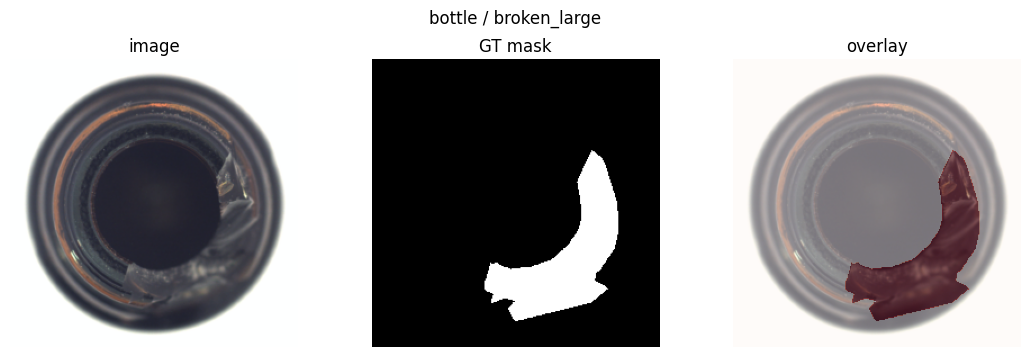

[cable] train=179 val=45 test_normal=58 test_anom=92
  saved -> /kaggle/working/results/figs/mask_sanity_cable.png


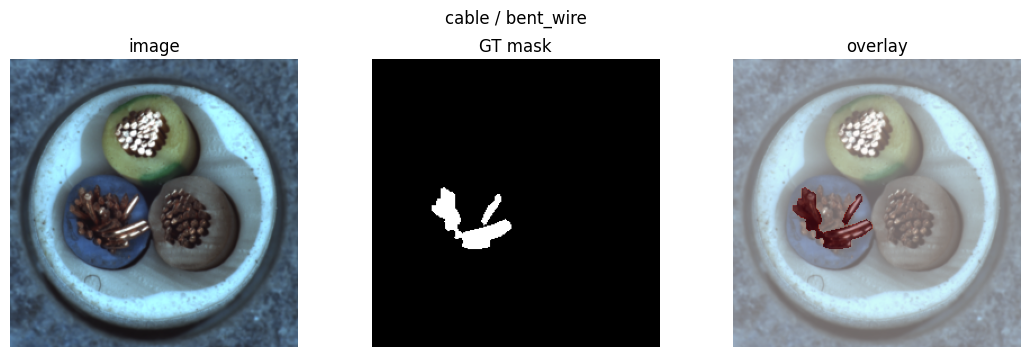

[capsule] train=175 val=44 test_normal=23 test_anom=109
  saved -> /kaggle/working/results/figs/mask_sanity_capsule.png


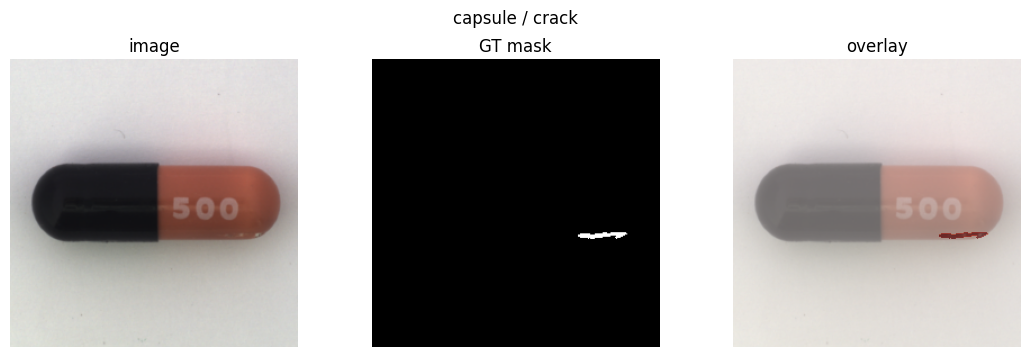

[carpet] train=224 val=56 test_normal=28 test_anom=89
  saved -> /kaggle/working/results/figs/mask_sanity_carpet.png


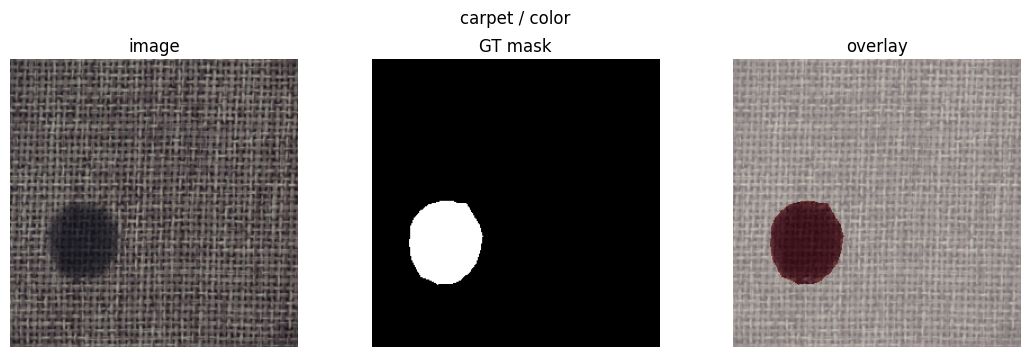

[grid] train=211 val=53 test_normal=21 test_anom=57
  saved -> /kaggle/working/results/figs/mask_sanity_grid.png


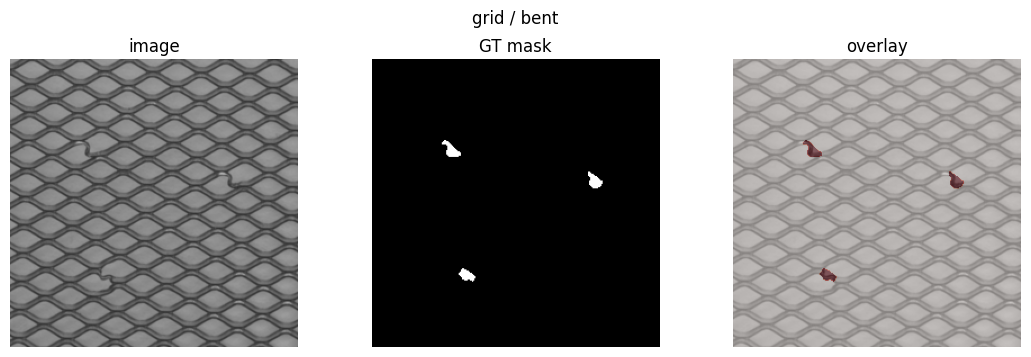

[hazelnut] train=313 val=78 test_normal=40 test_anom=70
  saved -> /kaggle/working/results/figs/mask_sanity_hazelnut.png


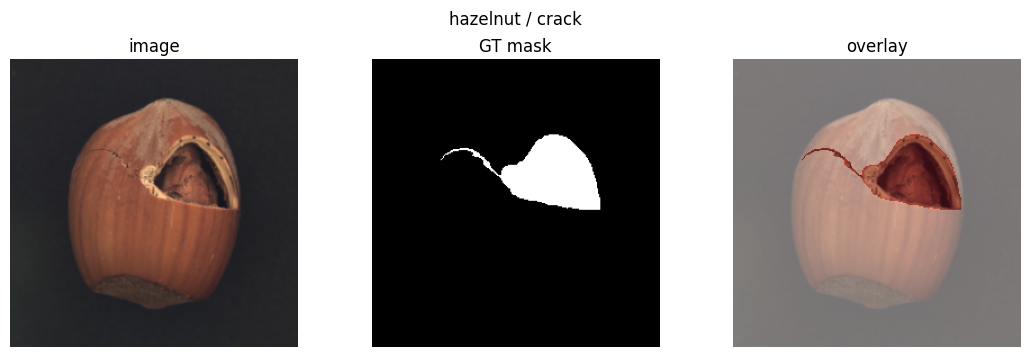

[leather] train=196 val=49 test_normal=32 test_anom=92
  saved -> /kaggle/working/results/figs/mask_sanity_leather.png


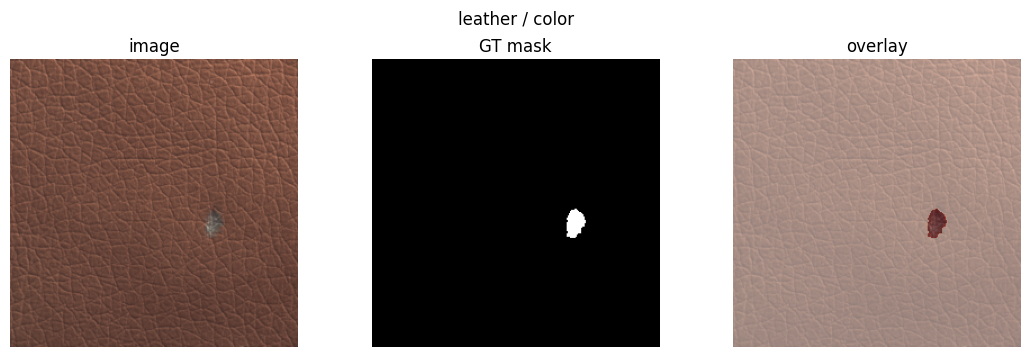

[metal_nut] train=176 val=44 test_normal=22 test_anom=93
  saved -> /kaggle/working/results/figs/mask_sanity_metal_nut.png


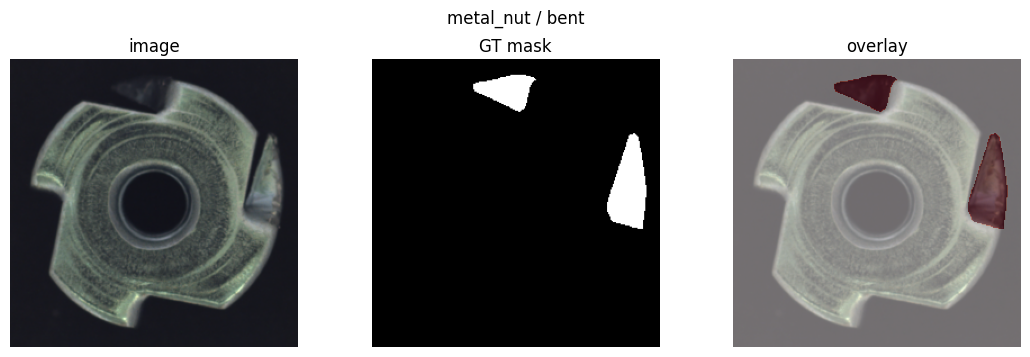

[pill] train=214 val=53 test_normal=26 test_anom=141
  saved -> /kaggle/working/results/figs/mask_sanity_pill.png


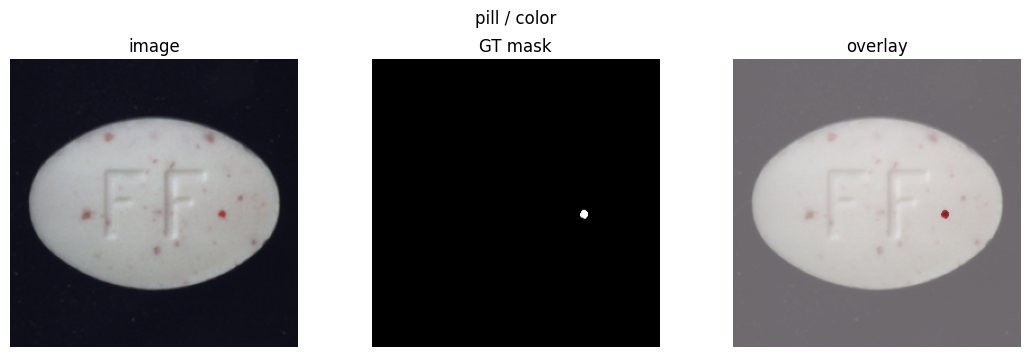

[screw] train=256 val=64 test_normal=41 test_anom=119
  saved -> /kaggle/working/results/figs/mask_sanity_screw.png


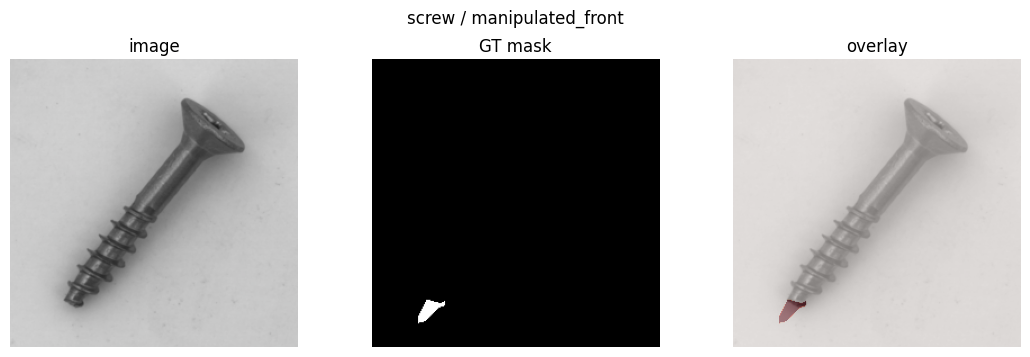

[tile] train=184 val=46 test_normal=33 test_anom=84
  saved -> /kaggle/working/results/figs/mask_sanity_tile.png


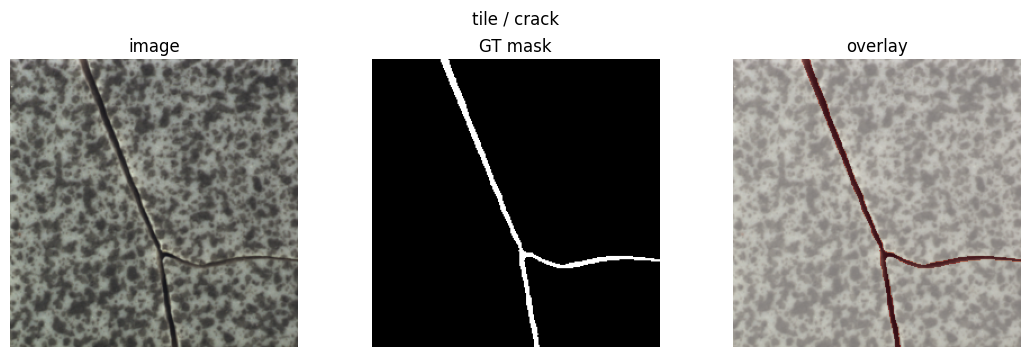

[toothbrush] train=48 val=12 test_normal=12 test_anom=30
  saved -> /kaggle/working/results/figs/mask_sanity_toothbrush.png


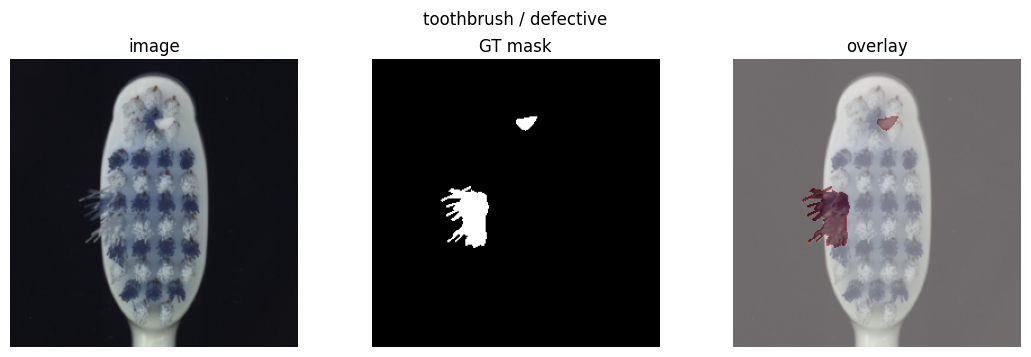

[transistor] train=170 val=43 test_normal=60 test_anom=40
  saved -> /kaggle/working/results/figs/mask_sanity_transistor.png


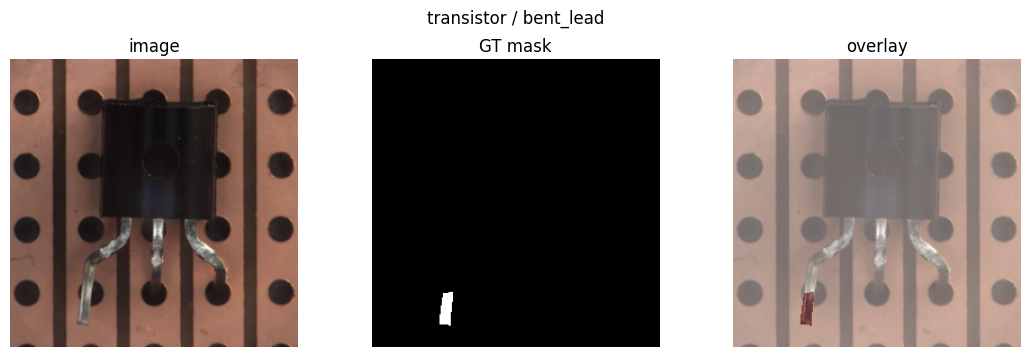

[wood] train=198 val=49 test_normal=19 test_anom=60
  saved -> /kaggle/working/results/figs/mask_sanity_wood.png


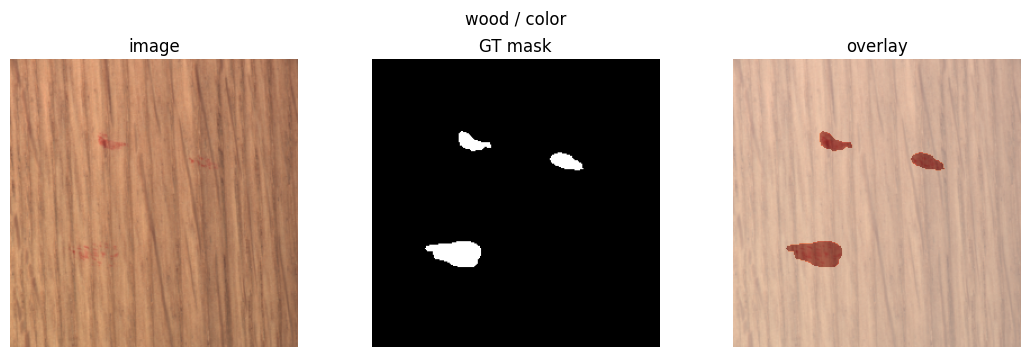

[zipper] train=192 val=48 test_normal=32 test_anom=119
  saved -> /kaggle/working/results/figs/mask_sanity_zipper.png


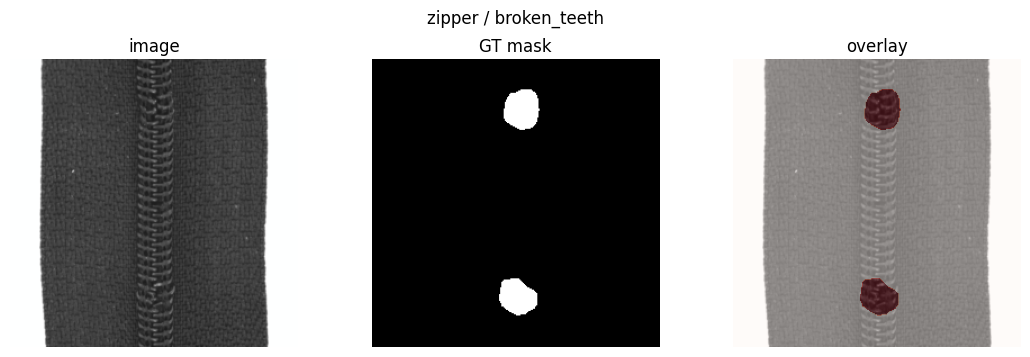


Saved 15 mask sanity-check images to /kaggle/working/results/figs


In [4]:
# ── Cell 4: Sanity check — GT mask for ALL classes (saved to disk) ─
def sanity_check(category, save=True):
    tr, va, te = (MVTecDataset(category, s) for s in ("train","val","test"))
    labels = [l for _, l, _ in te.items]
    print(f"[{category}] train={len(tr)} val={len(va)} "
          f"test_normal={labels.count(0)} test_anom={labels.count(1)}")
    check_masks(te)

    anom_idxs = [i for i, (_, l, _) in enumerate(te.items) if l == 1]
    if not anom_idxs:
        print(f"  no anomalous test images for {category}, skipping mask plot")
        return None

    j = anom_idxs[0]
    x, _, mask, p = te[j]
    img = np.clip(x.permute(1, 2, 0).numpy() * IMNET_STD + IMNET_MEAN, 0, 1)

    fig, ax = plt.subplots(1, 3, figsize=(11, 3.6))
    ax[0].imshow(img); ax[0].set_title("image")
    ax[1].imshow(mask[0], cmap="gray"); ax[1].set_title("GT mask")
    ax[2].imshow(img); ax[2].imshow(mask[0], cmap="Reds", alpha=.4); ax[2].set_title("overlay")
    for a in ax:
        a.axis("off")
    plt.suptitle(f"{category} / {Path(p).parent.name}")
    plt.tight_layout()

    out_path = None
    if save:
        out_path = CFG.out_dir / "figs" / f"mask_sanity_{category}.png"
        plt.savefig(out_path, dpi=150)
        print(f"  saved -> {out_path}")

    plt.show()
    plt.close(fig)
    return out_path

saved_mask_figs = []
for c in CATEGORIES:                      # all classes, not just the first two
    out_path = sanity_check(c)
    if out_path is not None:
        saved_mask_figs.append(out_path)

print(f"\nSaved {len(saved_mask_figs)} mask sanity-check images to {CFG.out_dir / 'figs'}")


## 2. Shared backbone + common model interface

All three baselines subclass `AnomalyModel`. The evaluation code never touches anything else.


In [5]:
# ── Cell 5: Shared ResNet-18 feature extractor ───────────────────
class ResNetFeatures(nn.Module):
    """Returns layer1/layer2/layer3 feature maps."""
    def __init__(self):
        super().__init__()
        net = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1).eval()
        for p in net.parameters(): p.requires_grad_(False)
        self.stem = nn.Sequential(net.conv1, net.bn1, net.relu, net.maxpool)
        self.l1, self.l2, self.l3 = net.layer1, net.layer2, net.layer3

    @torch.no_grad()
    def forward(self, x):
        x  = self.stem(x)
        f1 = self.l1(x); f2 = self.l2(f1); f3 = self.l3(f2)
        return f1, f2, f3

BACKBONE = ResNetFeatures().to(DEVICE).eval()
if torch.cuda.device_count() > 1:
    BACKBONE = nn.DataParallel(BACKBONE)
    print("Backbone on", torch.cuda.device_count(), "GPUs")

def gaussian_smooth(amap, sigma=4.0):
    k = int(2*round(3*sigma)+1)
    g = torch.exp(-((torch.arange(k, device=amap.device)-k//2)**2)/(2*sigma**2))
    g = g/g.sum()
    amap = F.conv2d(amap, g.view(1,1,1,k), padding=(0,k//2))
    amap = F.conv2d(amap, g.view(1,1,k,1), padding=(k//2,0))
    return amap

def upsample_smooth(amap, size=None, sigma=4.0):
    """(B,1,h,w) -> (B,crop,crop) smoothed."""
    size = size or CFG.center_crop
    amap = F.interpolate(amap, size=size, mode="bilinear", align_corners=False)
    return gaussian_smooth(amap, sigma).squeeze(1)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 377MB/s]


Backbone on 2 GPUs


In [6]:
# ── Cell 6: Common interface ─────────────────────────────────────
class AnomalyModel(ABC):
    name = "base"
    @abstractmethod
    def fit(self, train_loader): ...
    @abstractmethod
    @torch.no_grad()
    def score_batch(self, x): 
        """x: (B,3,H,W) -> anomaly map (B, crop, crop) as a torch tensor on CPU"""
        ...
    def extra_metadata(self): return {}

    @torch.no_grad()
    def score(self, loader):
        maps, labels, masks, paths = [], [], [], []
        for x, y, m, p in loader:
            amap = self.score_batch(x.to(DEVICE, non_blocking=True))
            maps.append(amap.cpu()); masks.append(m.squeeze(1))
            labels += list(y.numpy()); paths += list(p)
        maps  = torch.cat(maps).float()
        masks = torch.cat(masks).float()
        img_scores = maps.flatten(1).max(1).values.numpy()
        return img_scores, maps.numpy(), np.array(labels), masks.numpy(), paths


## 3. Baseline 1 — PaDiM
Concatenate layer1–3 features, keep a random subset of `d=100` channels, fit a Gaussian
(mean + regularized covariance) at every spatial position, score with Mahalanobis distance.


In [7]:
# ── Cell 7: PaDiM ────────────────────────────────────────────────
class PaDiM(AnomalyModel):
    name = "padim"
    TOTAL_C = 64 + 128 + 256      # resnet18 layers 1,2,3

    def __init__(self, d=CFG.padim_d, seed=CFG.seed):
        self.d = d
        idx = np.random.RandomState(seed).choice(self.TOTAL_C, d, replace=False)
        self.channel_idx = torch.from_numpy(np.sort(idx)).long()

    @torch.no_grad()
    def _embed(self, x):
        f1, f2, f3 = BACKBONE(x)
        h, w = f1.shape[-2:]
        f = torch.cat([f1,
                       F.interpolate(f2, (h,w), mode="nearest"),
                       F.interpolate(f3, (h,w), mode="nearest")], 1)
        return f[:, self.channel_idx.to(f.device)]

    def fit(self, train_loader):
        embs = []
        for x, *_ in train_loader:
            embs.append(self._embed(x.to(DEVICE)).cpu())
        E = torch.cat(embs)                              # (N,d,H,W)
        N, d, H, W = E.shape
        self.hw = (H, W)
        E = E.permute(0,2,3,1).reshape(N, H*W, d)
        self.mean = E.mean(0)                            # (HW,d)
        Ec = E - self.mean.unsqueeze(0)
        eye = torch.eye(d) * 0.01
        cov = torch.empty(H*W, d, d)
        for p in range(H*W):                             # loop = low peak RAM
            v = Ec[:, p, :]
            cov[p] = (v.T @ v)/(N-1) + eye
        self.cov_inv = torch.linalg.inv(cov).to(DEVICE)
        self.mean = self.mean.to(DEVICE)
        del E, Ec, cov, embs; gc.collect()
        return self

    @torch.no_grad()
    def score_batch(self, x):
        f = self._embed(x)
        B, d = f.shape[0], f.shape[1]
        H, W = self.hw
        f = f.permute(0,2,3,1).reshape(B, H*W, d)
        delta = f - self.mean.unsqueeze(0)
        md2 = torch.einsum("bpd,pde,bpe->bp", delta, self.cov_inv, delta)
        amap = md2.clamp(min=0).sqrt().reshape(B,1,H,W)
        return upsample_smooth(amap)

    def extra_metadata(self):
        return {"d_reduced": self.d, "grid": list(self.hw)}


## 4. Baseline 2 — PatchCore
Locally-aggregated layer2+layer3 features → greedy **coreset** subsampling of the memory bank →
k-NN distance scoring, with the paper's image-score reweighting.


In [8]:
# ── Cell 8: PatchCore ────────────────────────────────────────────
class PatchCore(AnomalyModel):
    name = "patchcore"

    def __init__(self, coreset_ratio=CFG.pc_coreset_ratio,
                 n_neighbors=CFG.pc_n_neighbors, pool=CFG.pc_patch_pool):
        self.coreset_ratio, self.k, self.pool = coreset_ratio, n_neighbors, pool

    @torch.no_grad()
    def _patch_features(self, x):
        """layer2 + layer3, local avg-pool aggregation, concatenated at layer2 resolution."""
        _, f2, f3 = BACKBONE(x)
        h, w = f2.shape[-2:]
        pad = self.pool // 2
        f2 = F.avg_pool2d(f2, self.pool, 1, pad)
        f3 = F.avg_pool2d(f3, self.pool, 1, pad)
        f3 = F.interpolate(f3, (h, w), mode="bilinear", align_corners=False)
        f = torch.cat([f2, f3], 1)                        # (B,C,h,w)
        B, C = f.shape[:2]
        self.hw = (h, w)
        return f.permute(0,2,3,1).reshape(B*h*w, C)       # (B*hw, C)

    @staticmethod
    def _greedy_coreset(feats, n_select, seed=CFG.seed):
        """k-center-greedy on GPU; O(n_select * N) distance updates."""
        N = feats.shape[0]
        n_select = min(n_select, N)
        g = torch.Generator(device="cpu").manual_seed(seed)
        start = int(torch.randint(N, (1,), generator=g))
        selected = [start]
        dist = torch.cdist(feats, feats[start:start+1]).squeeze(1)
        for _ in range(n_select - 1):
            i = int(torch.argmax(dist))
            selected.append(i)
            dist = torch.minimum(dist, torch.cdist(feats, feats[i:i+1]).squeeze(1))
        return torch.tensor(selected, dtype=torch.long)

    def fit(self, train_loader):
        feats = []
        for x, *_ in train_loader:
            feats.append(self._patch_features(x.to(DEVICE)).cpu())
        F_all = torch.cat(feats)                           # (N_patches, C)
        n_sel = max(1, int(self.coreset_ratio * F_all.shape[0]))
        Fg = F_all.to(DEVICE)
        idx = self._greedy_coreset(Fg, n_sel)
        self.bank = Fg[idx.to(DEVICE)].contiguous()        # (M, C) kept on GPU
        self.bank_size = self.bank.shape[0]
        self.bank_mb = self.bank.numel() * 4 / 1e6
        print(f"  memory bank: {self.bank_size} / {F_all.shape[0]} patches "
              f"({self.bank_mb:.1f} MB)")
        del F_all, Fg, feats; gc.collect(); torch.cuda.empty_cache()
        return self

    @torch.no_grad()
    def score_batch(self, x):
        f = self._patch_features(x)                        # (B*hw, C)
        h, w = self.hw
        B = f.shape[0] // (h*w)
        # chunked k-NN to bound memory
        mins, knn = [], []
        for chunk in torch.split(f, 4096):
            d = torch.cdist(chunk, self.bank)               # (c, M)
            topk = torch.topk(d, min(self.k, self.bank.shape[0]),
                              dim=1, largest=False).values
            mins.append(topk[:, 0]); knn.append(topk)
        patch_d = torch.cat(mins)                           # (B*hw,)
        topk    = torch.cat(knn)
        amap = patch_d.reshape(B, 1, h, w)

        maps = upsample_smooth(amap)                        # (B,crop,crop)
        # PatchCore image-level reweighting on the max-distance patch
        flat = patch_d.reshape(B, h*w)
        pos  = flat.argmax(1)
        tk   = topk.reshape(B, h*w, -1)[torch.arange(B), pos]     # (B,k)
        w_re = 1 - torch.softmax(tk, dim=1)[:, 0]                  # (B,)
        self._last_image_score = (w_re * flat.max(1).values).cpu().numpy()
        return maps

    @torch.no_grad()
    def score(self, loader):
        """Override to use the reweighted image score instead of map-max."""
        maps, labels, masks, paths, iscores = [], [], [], [], []
        for x, y, m, p in loader:
            amap = self.score_batch(x.to(DEVICE, non_blocking=True))
            maps.append(amap.cpu()); masks.append(m.squeeze(1))
            iscores.append(self._last_image_score)
            labels += list(y.numpy()); paths += list(p)
        maps  = torch.cat(maps).float(); masks = torch.cat(masks).float()
        return (np.concatenate(iscores), maps.numpy(),
                np.array(labels), masks.numpy(), paths)

    def extra_metadata(self):
        return {"coreset_ratio": self.coreset_ratio, "bank_size": self.bank_size,
                "bank_mb": round(self.bank_mb, 2), "k": self.k}


## 5. Baseline 3 — EfficientAD (reduced)
Patch-Description-Network student trained to regress a frozen teacher, plus an autoencoder
branch for logical anomalies. Anomaly map = student–teacher error + student–autoencoder error.

**Deviation from the paper:** the teacher here is distilled from ResNet-18 at run time instead
of loading the official WideResNet-101-distilled PDN weights (not available offline). Speed
characteristics are representative; absolute AUROC will be below published numbers.


In [9]:
# ── Cell 9: EfficientAD (reduced) ────────────────────────────────
class PDN(nn.Module):
    """Patch Description Network (small variant), stride-4 output."""
    def __init__(self, out_ch=CFG.ead_channels):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 128, 4, 1, 3), nn.ReLU(inplace=True), nn.AvgPool2d(2,2),
            nn.Conv2d(128, 256, 4, 1, 3), nn.ReLU(inplace=True), nn.AvgPool2d(2,2),
            nn.Conv2d(256, 256, 3, 1, 1), nn.ReLU(inplace=True),
            nn.Conv2d(256, out_ch, 4, 1, 0),
        )
    def forward(self, x): return self.net(x)

class ConvAE(nn.Module):
    """Autoencoder branch — global context for logical anomalies."""
    def __init__(self, out_ch=CFG.ead_channels):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv2d(3,32,4,2,1), nn.ReLU(True), nn.Conv2d(32,64,4,2,1), nn.ReLU(True),
            nn.Conv2d(64,64,4,2,1), nn.ReLU(True), nn.Conv2d(64,64,4,2,1), nn.ReLU(True),
            nn.Conv2d(64,64,4,2,1), nn.ReLU(True),
        )
        self.dec = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(64,64,3,1,1), nn.ReLU(True),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(64,64,3,1,1), nn.ReLU(True),
            nn.Conv2d(64,out_ch,3,1,1),
        )
    def forward(self, x): return self.dec(self.enc(x))

class EfficientAD(AnomalyModel):
    name = "efficientad"

    def __init__(self, epochs=CFG.ead_epochs, lr=CFG.ead_lr, ch=CFG.ead_channels):
        self.epochs, self.lr, self.ch = epochs, lr, ch

    @torch.no_grad()
    def _teacher_target(self, x, size):
        """Frozen ResNet-18 layer2 projected to `ch` channels — stands in for the
        officially distilled PDN teacher."""
        _, f2, _ = BACKBONE(x)
        t = self.proj(f2)
        return F.interpolate(t, size=size, mode="bilinear", align_corners=False)

    def fit(self, train_loader):
        set_seed()
        self.student = PDN(self.ch).to(DEVICE)
        self.ae      = ConvAE(self.ch).to(DEVICE)
        self.proj    = nn.Conv2d(128, self.ch, 1).to(DEVICE)   # teacher projection (frozen)
        for p in self.proj.parameters(): p.requires_grad_(False)

        opt = torch.optim.Adam(list(self.student.parameters()) + list(self.ae.parameters()),
                               lr=self.lr, weight_decay=1e-5)
        self.student.train(); self.ae.train()
        for ep in range(self.epochs):
            tot, n = 0.0, 0
            for x, *_ in train_loader:
                x = x.to(DEVICE, non_blocking=True)
                s = self.student(x)
                t = self._teacher_target(x, s.shape[-2:])
                a = F.interpolate(self.ae(x), s.shape[-2:], mode="bilinear", align_corners=False)
                loss = F.mse_loss(s, t) + F.mse_loss(a, t)   # ST loss + AE loss
                opt.zero_grad(); loss.backward(); opt.step()
                tot += loss.item()*x.size(0); n += x.size(0)
            if ep % max(1, self.epochs//4) == 0 or ep == self.epochs-1:
                print(f"  epoch {ep+1}/{self.epochs} loss={tot/n:.4f}")
        self.student.eval(); self.ae.eval()

        # normalization stats from TRAINING normals (paper uses quantiles) so the two
        # error branches are comparable before summing
        st, ae = [], []
        with torch.no_grad():
            for x, *_ in train_loader:
                a1, a2 = self._raw_maps(x.to(DEVICE))
                st.append(a1.flatten()); ae.append(a2.flatten())
        st = torch.cat(st); ae = torch.cat(ae)
        self.q_st = (st.mean().item(), st.std().item() + 1e-8)
        self.q_ae = (ae.mean().item(), ae.std().item() + 1e-8)
        return self

    @torch.no_grad()
    def _raw_maps(self, x):
        s = self.student(x)
        t = self._teacher_target(x, s.shape[-2:])
        a = F.interpolate(self.ae(x), s.shape[-2:], mode="bilinear", align_corners=False)
        m_st = ((s - t)**2).mean(1, keepdim=True)      # structural anomalies
        m_ae = ((s - a)**2).mean(1, keepdim=True)      # logical anomalies
        return m_st, m_ae

    @torch.no_grad()
    def score_batch(self, x):
        m_st, m_ae = self._raw_maps(x)
        m_st = (m_st - self.q_st[0]) / self.q_st[1]
        m_ae = (m_ae - self.q_ae[0]) / self.q_ae[1]
        return upsample_smooth(0.5*(m_st + m_ae))

    def extra_metadata(self):
        return {"epochs": self.epochs, "lr": self.lr, "channels": self.ch,
                "teacher": "resnet18-layer2-proj (NOT official distilled PDN)"}


## 6. Metrics, thresholds, perturbations (model-agnostic)

In [10]:
# ── Cell 10: Metrics ─────────────────────────────────────────────
def image_auroc(labels, scores):
    labels = np.asarray(labels)
    if labels.min() == labels.max(): return np.nan
    return roc_auc_score(labels, scores)

def pixel_auroc(masks, maps, max_pixels=8_000_000):
    y = masks.reshape(-1); s = maps.reshape(-1)
    if y.max() == y.min(): return np.nan
    if len(y) > max_pixels:
        idx = np.random.RandomState(CFG.seed).choice(len(y), max_pixels, replace=False)
        y, s = y[idx], s[idx]
    return roc_auc_score(y, s)

def deployment_metrics(labels, scores, thr):
    labels = np.asarray(labels); pred = (scores >= thr).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(labels, pred,
                                                  average="binary", zero_division=0)
    normal = labels == 0
    return dict(precision=p, recall=r, f1=f1,
                fpr=float(pred[normal].mean()) if normal.any() else np.nan,
                fnr=float((1-pred[~normal]).mean()) if (~normal).any() else np.nan,
                threshold=float(thr))

def oracle_threshold(labels, scores):
    """Best-F1 threshold from test labels — NOT deployment-valid, upper bound only."""
    cand = np.unique(scores)
    if len(cand) > 400:
        cand = np.quantile(scores, np.linspace(0, 1, 400))
    best = max(cand, key=lambda t: deployment_metrics(labels, scores, t)["f1"])
    return best

def threshold_sensitivity(labels, scores, base_thr, val_scores, deltas=(-0.5,-0.25,0.25,0.5)):
    """How much does F1 move if the threshold shifts by k standard deviations of the
    validation-normal score distribution? This is the most direct measure of
    'threshold stability' — the core claim of the paper."""
    sd = val_scores.std() + 1e-8
    out = {}
    for d in deltas:
        out[f"f1_shift_{d:+.2f}sd"] = deployment_metrics(labels, scores, base_thr + d*sd)["f1"]
    return out


In [11]:
# ── Cell 11: Perturbations (test-time only) ──────────────────────
def p_blur(s):       return lambda im: im.filter(ImageFilter.GaussianBlur(radius=s))
def p_brightness(f): return lambda im: ImageEnhance.Brightness(im).enhance(f)
def p_jpeg(q):
    def fn(im):
        b = io.BytesIO(); im.save(b, format="JPEG", quality=q); b.seek(0)
        return Image.open(b).convert("RGB")
    return fn
def p_shift(px):
    def fn(im):
        w, h = im.size
        return im.transform((w,h), Image.AFFINE, (1,0,px,0,1,px), resample=Image.BILINEAR)
    return fn

PERTURBATIONS = (
    [(f"blur_s{s}", p_blur(s)) for s in CFG.blur_sigmas] +
    [(f"bright_{f}", p_brightness(f)) for f in CFG.brightness_factors] +
    [(f"jpeg_q{q}", p_jpeg(q)) for q in CFG.jpeg_qualities] +
    [(f"shift_{p}px", p_shift(p)) for p in CFG.shift_pixels]
)
print(len(PERTURBATIONS), "perturbations:", [n for n,_ in PERTURBATIONS])


10 perturbations: ['blur_s0.5', 'blur_s1.0', 'blur_s1.5', 'bright_0.9', 'bright_1.1', 'jpeg_q90', 'jpeg_q70', 'jpeg_q50', 'shift_4px', 'shift_8px']


## 7. Main loop — every model × every category

Start with `RUN_MODELS = ["padim"]`, `RUN_CATEGORIES = CATEGORIES[:1]`, `RUN_PERTURBED = False`
to validate the pipeline in a couple of minutes, then scale up.


In [12]:
# ── Cell 12: Run all models ──────────────────────────────────────
MODEL_REGISTRY = {"padim": PaDiM, "patchcore": PatchCore, "efficientad": EfficientAD}

RUN_MODELS     = ["padim", "patchcore", "efficientad"]
RUN_CATEGORIES = CATEGORIES
RUN_PERTURBED  = True

clean_rows, thr_rows, pert_rows, runtime_rows, meta_rows = [], [], [], [], []
val_stats = {}     # (model, category) -> dict(mu, sd, scores)

for mname in RUN_MODELS:
    print(f"\n{'='*60}\nMODEL: {mname}\n{'='*60}")
    for cat in RUN_CATEGORIES:
        set_seed()
        print(f"\n--- {mname} / {cat} ---")
        model = MODEL_REGISTRY[mname]()

        t0 = time.time()
        model.fit(make_loader(MVTecDataset(cat, "train"), shuffle=(mname=="efficientad")))
        fit_s = time.time() - t0

        # validation normals -> threshold source (never test labels)
        v_scores, *_ = model.score(make_loader(MVTecDataset(cat, "val")))
        val_stats[(mname, cat)] = dict(mu=float(v_scores.mean()),
                                       sd=float(v_scores.std())+1e-8, scores=v_scores)

        # clean test — timed after a warm-up batch
        test_loader = make_loader(MVTecDataset(cat, "test"))
        _ = model.score_batch(next(iter(test_loader))[0].to(DEVICE))   # warm-up
        if torch.cuda.is_available(): torch.cuda.synchronize()
        t0 = time.time()
        scores, maps, labels, masks, paths = model.score(test_loader)
        if torch.cuda.is_available(): torch.cuda.synchronize()
        ms_img = (time.time()-t0)/len(labels)*1000

        ia, pa = image_auroc(labels, scores), pixel_auroc(masks, maps)
        print(f"  image AUROC={ia:.4f}  pixel AUROC={pa:.4f}  {ms_img:.1f} ms/img  "
              f"(fit {fit_s:.0f}s)")

        pd.DataFrame(dict(path=paths, category=cat, model=mname,
                          label=labels, score=scores)).to_csv(
            CFG.out_dir/"clean"/f"{mname}_{cat}_scores.csv", index=False)
        np.save(CFG.out_dir/"maps"/f"{mname}_{cat}_maps.npy", maps.astype(np.float16))

        clean_rows.append(dict(model=mname, category=cat,
                               group="texture" if cat in TEXTURES else "object",
                               image_auroc=ia, pixel_auroc=pa, n_test=len(labels)))
        runtime_rows.append(dict(model=mname, category=cat, fit_s=fit_s,
                                 infer_ms_per_img=ms_img))
        meta_rows.append(dict(model=mname, category=cat, **model.extra_metadata()))

        # thresholds: per-category percentile + sensitivity + oracle
        for pc in CFG.percentiles:
            thr = float(np.percentile(v_scores, pc))
            row = dict(model=mname, category=cat, strategy=f"per_cat_p{pc}",
                       **deployment_metrics(labels, scores, thr))
            if pc == 97.5:
                row.update(threshold_sensitivity(labels, scores, thr, v_scores))
            thr_rows.append(row)
        thr_rows.append(dict(model=mname, category=cat, strategy="oracle",
                             **deployment_metrics(labels, scores,
                                                  oracle_threshold(labels, scores))))

        if RUN_PERTURBED:
            for pn, pf in PERTURBATIONS:
                ps, pmaps, pl, pm, _ = model.score(
                    make_loader(MVTecDataset(cat, "test", perturb_fn=pf)))
                thr = float(np.percentile(v_scores, 97.5))
                pert_rows.append(dict(model=mname, category=cat, perturbation=pn,
                                      image_auroc=image_auroc(pl, ps),
                                      pixel_auroc=pixel_auroc(pm, pmaps),
                                      f1=deployment_metrics(pl, ps, thr)["f1"],
                                      seed=CFG.seed))
                del pmaps, pm; gc.collect()

        del model, maps, masks; gc.collect(); torch.cuda.empty_cache()

clean_df = pd.DataFrame(clean_rows); clean_df.to_csv(CFG.out_dir/"clean"/"clean_summary.csv", index=False)
run_df   = pd.DataFrame(runtime_rows); run_df.to_csv(CFG.out_dir/"runtime"/"runtime.csv", index=False)
pd.DataFrame(meta_rows).to_csv(CFG.out_dir/"runtime"/"model_metadata.csv", index=False)
if pert_rows:
    pert_df = pd.DataFrame(pert_rows); pert_df.to_csv(CFG.out_dir/"perturbed"/"perturbed.csv", index=False)
print("\nDone.")
clean_df.groupby("model")[["image_auroc","pixel_auroc"]].mean().round(4)



MODEL: padim

--- padim / bottle ---
  image AUROC=0.9952  pixel AUROC=0.9841  26.0 ms/img  (fit 10s)

--- padim / cable ---
  image AUROC=0.8638  pixel AUROC=0.9574  35.8 ms/img  (fit 12s)

--- padim / capsule ---
  image AUROC=0.8951  pixel AUROC=0.9856  34.8 ms/img  (fit 11s)

--- padim / carpet ---
  image AUROC=0.9811  pixel AUROC=0.9885  38.0 ms/img  (fit 15s)

--- padim / grid ---
  image AUROC=0.9081  pixel AUROC=0.9129  29.1 ms/img  (fit 13s)

--- padim / hazelnut ---
  image AUROC=0.9289  pixel AUROC=0.9818  42.6 ms/img  (fit 22s)

--- padim / leather ---
  image AUROC=1.0000  pixel AUROC=0.9914  38.7 ms/img  (fit 14s)

--- padim / metal_nut ---
  image AUROC=0.9550  pixel AUROC=0.9682  23.2 ms/img  (fit 9s)

--- padim / pill ---
  image AUROC=0.8254  pixel AUROC=0.9537  26.1 ms/img  (fit 11s)

--- padim / screw ---
  image AUROC=0.7963  pixel AUROC=0.9795  21.2 ms/img  (fit 12s)

--- padim / tile ---
  image AUROC=0.9405  pixel AUROC=0.9059  32.5 ms/img  (fit 11s)

--- padi

,image_auroc,pixel_auroc
model,,
efficientad,0.6957,0.8313
padim,0.9221,0.9655
patchcore,0.9767,0.9721


In [13]:
# ── Cell 13: Global + transferred thresholds ─────────────────────
# Scores are not comparable across categories, so z-normalize by each category's own
# validation-normal statistics before pooling.
for mname in RUN_MODELS:
    pooled = np.concatenate([
        (val_stats[(mname,c)]["scores"] - val_stats[(mname,c)]["mu"]) /
         val_stats[(mname,c)]["sd"] for c in RUN_CATEGORIES])
    for pc in CFG.percentiles:
        g_thr = float(np.percentile(pooled, pc))
        for cat in RUN_CATEGORIES:
            df = pd.read_csv(CFG.out_dir/"clean"/f"{mname}_{cat}_scores.csv")
            v = val_stats[(mname,cat)]
            z = (df["score"].values - v["mu"]) / v["sd"]
            thr_rows.append(dict(model=mname, category=cat, strategy=f"global_z_p{pc}",
                                 **deployment_metrics(df["label"].values, z, g_thr)))

    # THRESHOLD TRANSFER: tune on the first 10 categories, apply unchanged to the rest
    if len(RUN_CATEGORIES) >= 4:
        n_tune = int(round(0.67*len(RUN_CATEGORIES)))
        tune_cats, held_cats = RUN_CATEGORIES[:n_tune], RUN_CATEGORIES[n_tune:]
        tuned = np.concatenate([
            (val_stats[(mname,c)]["scores"] - val_stats[(mname,c)]["mu"]) /
             val_stats[(mname,c)]["sd"] for c in tune_cats])
        t_thr = float(np.percentile(tuned, 97.5))
        for cat in held_cats:
            df = pd.read_csv(CFG.out_dir/"clean"/f"{mname}_{cat}_scores.csv")
            v = val_stats[(mname,cat)]
            z = (df["score"].values - v["mu"]) / v["sd"]
            thr_rows.append(dict(model=mname, category=cat, strategy="transfer_p97.5",
                                 **deployment_metrics(df["label"].values, z, t_thr)))

thr_df = pd.DataFrame(thr_rows)
thr_df.to_csv(CFG.out_dir/"thresholds"/"thresholds.csv", index=False)
thr_df.groupby(["model","strategy"])[["f1","fpr","fnr"]].mean().round(3)


f1    fpr    fnr
model       strategy                           
efficientad global_z_p95.0  0.396  0.068  0.692
            global_z_p97.5  0.354  0.024  0.730
            global_z_p99.0  0.323  0.013  0.758
            oracle          0.862  0.741  0.036
            per_cat_p95.0   0.388  0.070  0.696
            per_cat_p97.5   0.370  0.047  0.717
            per_cat_p99.0   0.344  0.028  0.739
            transfer_p97.5  0.400  0.036  0.709
padim       global_z_p95.0  0.817  0.116  0.249
            global_z_p97.5  0.761  0.077  0.319
            global_z_p99.0  0.692  0.049  0.396
            oracle          0.934  0.276  0.038
            per_cat_p95.0   0.818  0.152  0.233
            per_cat_p97.5   0.788  0.097  0.277
            per_cat_p99.0   0.739  0.068  0.346
            transfer_p97.5  0.807  0.106  0.268
patchcore   global_z_p95.0  0.944  0.142  0.056
            global_z_p97.5  0.930  0.109  0.086
            global_z_p99.0  0.905  0.060  0.135
            oracle          0.971  0.103  0.022
            per_cat_p95.0   0.943  0.168  0.051
            per_cat_p97.5   0.942  0.124  0.064
            per_cat_p99.0   0.930  0.089  0.090
            transfer_p97.5  0.947  0.154  0.032

## 8. Paper tables & figures

In [14]:
# ── Cell 14: Table 1 — clean benchmark ───────────────────────────
t1 = clean_df.pivot_table(index="category", columns="model",
                          values=["image_auroc","pixel_auroc"]).round(4)
display(t1)
print("\nTexture vs object subgroup:")
display(clean_df.groupby(["model","group"])[["image_auroc","pixel_auroc"]].mean().round(4))

print("\nRuntime (ms/img, after warm-up):")
display(run_df.groupby("model")[["fit_s","infer_ms_per_img"]].mean().round(2))


image_auroc                   pixel_auroc                  
model      efficientad   padim patchcore efficientad   padim patchcore
category                                                              
bottle          0.9381  0.9952    1.0000      0.8306  0.9841    0.9826
cable           0.5144  0.8638    0.9940      0.7804  0.9574    0.9834
capsule         0.3753  0.8951    0.9817      0.9001  0.9856    0.9879
carpet          0.7099  0.9811    0.9856      0.9416  0.9885    0.9866
grid            0.7243  0.9081    0.9632      0.6252  0.9129    0.9469
hazelnut        0.9175  0.9289    1.0000      0.9543  0.9818    0.9867
leather         0.7928  1.0000    1.0000      0.9853  0.9914    0.9909
metal_nut       0.5288  0.9550    0.9941      0.6871  0.9682    0.9827
pill            0.6211  0.8254    0.9509      0.8489  0.9537    0.9751
screw           0.9758  0.7963    0.9252      0.9336  0.9795    0.9859
tile            0.8074  0.9405    0.9949      0.8414  0.9059    0.9243
toothbrush      0.4194  0.9444    0.9222      0.8207  0.9898    0.9891
transistor      0.6733  0.9392    0.9875      0.6233  0.9725    0.9566
wood            0.7851  0.9877    0.9912      0.8507  0.9287    0.9178
zipper          0.6528  0.8713    0.9603      0.8456  0.9825    0.9847


Texture vs object subgroup:


image_auroc  pixel_auroc
model       group                            
efficientad object        0.6617       0.8225
            texture       0.7639       0.8488
padim       object        0.9015       0.9755
            texture       0.9635       0.9455
patchcore   object        0.9716       0.9815
            texture       0.9870       0.9533


Runtime (ms/img, after warm-up):


,fit_s,infer_ms_per_img
model,,
efficientad,57.74,29.42
padim,11.90,32.14
patchcore,31.49,27.91


In [15]:
# ── Cell 15: Table 2 — threshold stability ───────────────────────
main = thr_df[thr_df["strategy"].isin(
    ["per_cat_p97.5","global_z_p97.5","transfer_p97.5","oracle"])]
display(main.pivot_table(index="model", columns="strategy",
                         values=["f1","fpr"]).round(3))

# the deployment gap: how far each strategy falls short of the oracle upper bound
piv = main.pivot_table(index=["model","category"], columns="strategy", values="f1")
if "oracle" in piv:
    for s in ["per_cat_p97.5","global_z_p97.5","transfer_p97.5"]:
        if s in piv: piv[f"gap_{s}"] = piv["oracle"] - piv[s]
    display(piv.filter(like="gap_").groupby("model").mean().round(3))

# threshold sensitivity: F1 under +/- k*sd shifts
sens = thr_df.filter(regex="^(model|f1_shift)").dropna()
if len(sens):
    print("\nThreshold sensitivity (mean F1 under threshold shift):")
    display(sens.groupby("model").mean(numeric_only=True).round(3))


f1                                                fpr  \
strategy    global_z_p97.5 oracle per_cat_p97.5 transfer_p97.5 global_z_p97.5   
model                                                                           
efficientad          0.354  0.862         0.370          0.400          0.024   
padim                0.761  0.934         0.788          0.807          0.077   
patchcore            0.930  0.971         0.942          0.947          0.109   

                                                 
strategy    oracle per_cat_p97.5 transfer_p97.5  
model                                            
efficientad  0.741         0.047          0.036  
padim        0.276         0.097          0.106  
patchcore    0.103         0.124          0.154

strategy,gap_per_cat_p97.5,gap_global_z_p97.5,gap_transfer_p97.5
model,,,
efficientad,0.491,0.508,0.418
padim,0.145,0.172,0.121
patchcore,0.030,0.041,0.021



Threshold sensitivity (mean F1 under threshold shift):


,f1_shift_-0.50sd,f1_shift_-0.25sd,f1_shift_+0.25sd,f1_shift_+0.50sd
model,,,,
efficientad,0.413,0.394,0.357,0.341
padim,0.828,0.808,0.771,0.747
patchcore,0.947,0.945,0.934,0.929


In [16]:
# ── Cell 16: Table 3 — robustness ────────────────────────────────
if pert_rows:
    base = clean_df.set_index(["model","category"])["image_auroc"]
    pert_df["auroc_drop"] = pert_df.apply(
        lambda r: base[(r["model"], r["category"])] - r["image_auroc"], axis=1)
    display(pert_df.pivot_table(index="perturbation", columns="model",
                                values="auroc_drop").round(4))
    print("\nMean AUROC drop per model (lower = more robust):")
    display(pert_df.groupby("model")[["auroc_drop"]].mean().round(4))


model,efficientad,padim,patchcore
perturbation,,,
blur_s0.5,0.0009,-0.0004,0.0003
blur_s1.0,0.0009,-0.0004,0.0019
blur_s1.5,0.0018,-0.0012,0.0027
bright_0.9,0.0194,0.0003,0.0002
bright_1.1,-0.0044,0.0008,-0.0004
jpeg_q50,0.0048,-0.0007,-0.0007
jpeg_q70,0.0060,0.0005,0.0003
jpeg_q90,0.0022,-0.0006,-0.0001
shift_4px,0.0792,0.2010,0.1999



Mean AUROC drop per model (lower = more robust):


,auroc_drop
model,
efficientad,0.0223
padim,0.0450
patchcore,0.0504


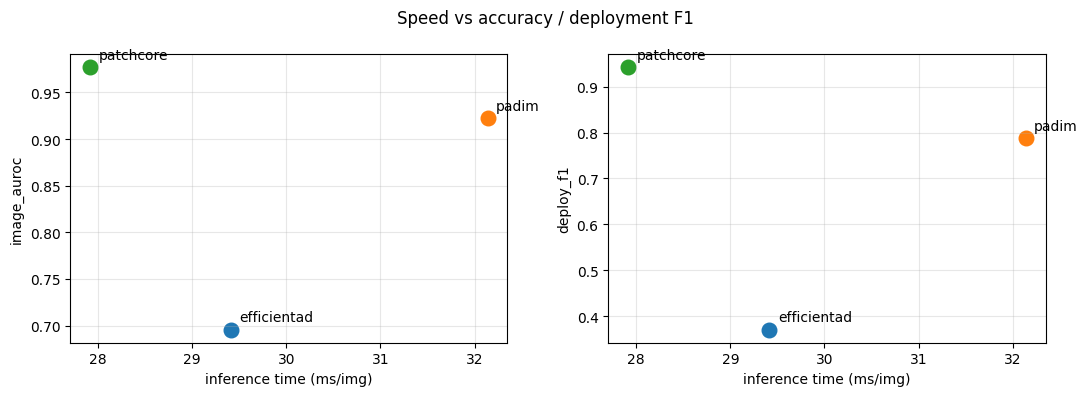

,image_auroc,infer_ms_per_img,deploy_f1
model,,,
efficientad,0.6957,29.4159,0.3705
padim,0.9221,32.1380,0.7884
patchcore,0.9767,27.9141,0.9420


In [17]:
# ── Cell 17: Figure — speed vs accuracy trade-off ────────────────
agg = (clean_df.groupby("model")["image_auroc"].mean().to_frame("image_auroc")
       .join(run_df.groupby("model")["infer_ms_per_img"].mean()))
f1_agg = thr_df[thr_df.strategy=="per_cat_p97.5"].groupby("model")["f1"].mean()
agg = agg.join(f1_agg.rename("deploy_f1"))

fig, ax = plt.subplots(1, 2, figsize=(11,4))
for i, ycol in enumerate(["image_auroc","deploy_f1"]):
    for m, r in agg.iterrows():
        ax[i].scatter(r["infer_ms_per_img"], r[ycol], s=110)
        ax[i].annotate(m, (r["infer_ms_per_img"], r[ycol]),
                       textcoords="offset points", xytext=(6,6))
    ax[i].set_xlabel("inference time (ms/img)"); ax[i].set_ylabel(ycol)
    ax[i].grid(alpha=.3)
plt.suptitle("Speed vs accuracy / deployment F1"); plt.tight_layout()
plt.savefig(CFG.out_dir/"figs"/"tradeoff.png", dpi=150); plt.show()
display(agg.round(4))


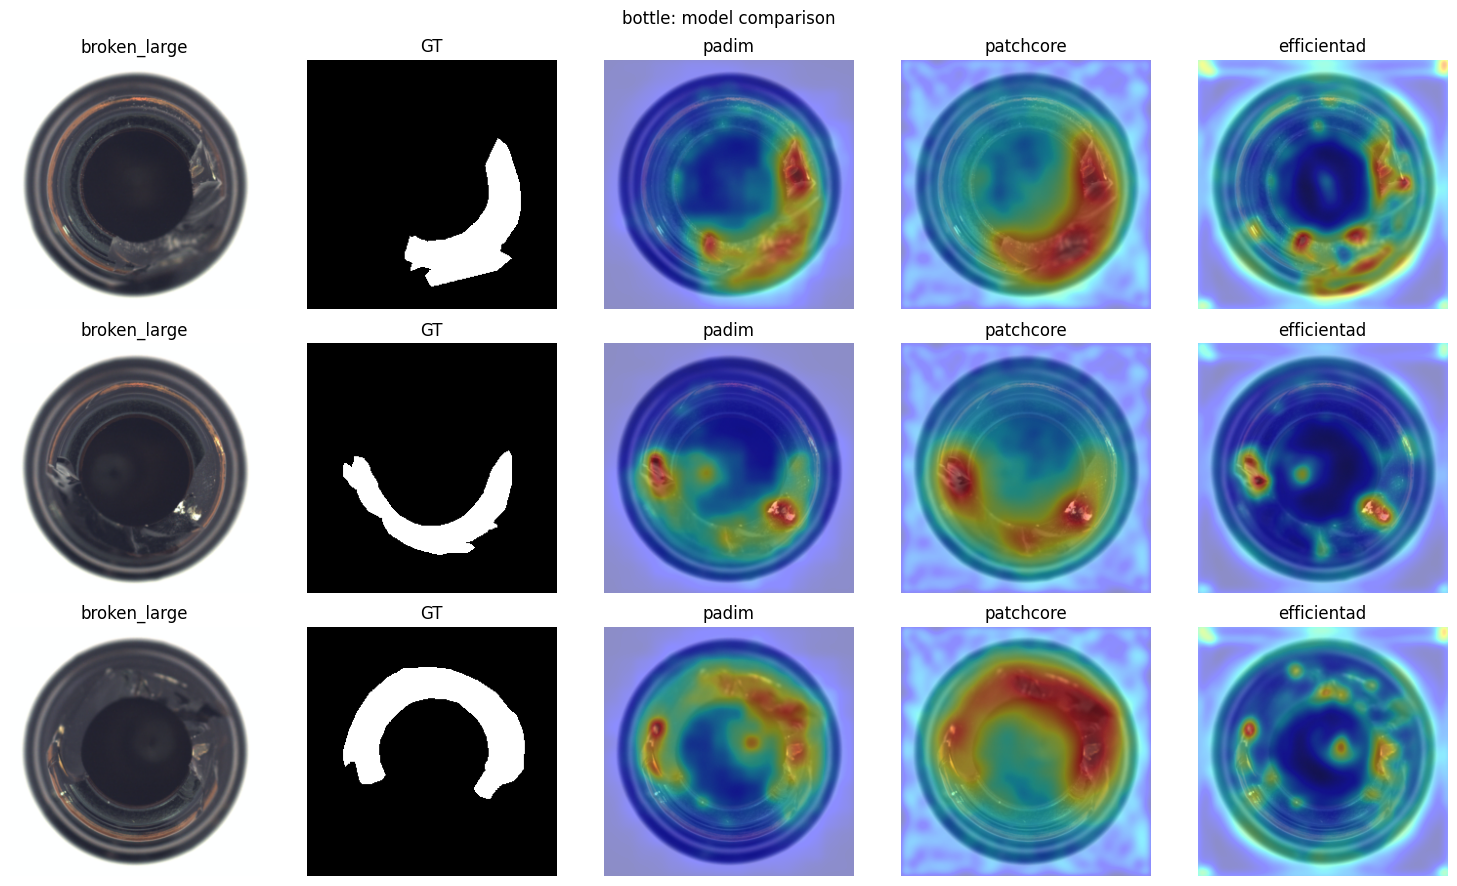

In [18]:
# ── Cell 18: Figure — qualitative comparison across models ───────
def compare_models(cat, n=3):
    te = MVTecDataset(cat, "test")
    ref = pd.read_csv(CFG.out_dir/"clean"/f"{RUN_MODELS[0]}_{cat}_scores.csv")
    rows = list(ref.index[ref["label"]==1][:n])
    maps = {m: np.load(CFG.out_dir/"maps"/f"{m}_{cat}_maps.npy").astype(np.float32)
            for m in RUN_MODELS}
    ncol = 2 + len(RUN_MODELS)
    fig, axes = plt.subplots(len(rows), ncol, figsize=(3*ncol, 3*len(rows)))
    axes = np.atleast_2d(axes)
    for r, i in enumerate(rows):
        x, _, mask, p = te[i]
        img = np.clip(x.permute(1,2,0).numpy()*IMNET_STD + IMNET_MEAN, 0, 1)
        axes[r,0].imshow(img); axes[r,0].set_title(Path(p).parent.name)
        axes[r,1].imshow(mask[0], cmap="gray"); axes[r,1].set_title("GT")
        for j, m in enumerate(RUN_MODELS):
            axes[r,2+j].imshow(img); axes[r,2+j].imshow(maps[m][i], cmap="jet", alpha=.45)
            axes[r,2+j].set_title(m)
        for a in axes[r]: a.axis("off")
    plt.suptitle(f"{cat}: model comparison"); plt.tight_layout()
    plt.savefig(CFG.out_dir/"figs"/f"qualitative_{cat}.png", dpi=150); plt.show()

compare_models(RUN_CATEGORIES[0])


In [19]:
# ── Cell 19: Freeze metadata ─────────────────────────────────────
meta = dict(
    models=RUN_MODELS, categories=RUN_CATEGORIES,
    img_size=CFG.img_size, center_crop=CFG.center_crop,
    val_frac=CFG.val_frac, seed=CFG.seed, batch_size=CFG.batch_size,
    percentiles=CFG.percentiles,
    perturbations=[n for n,_ in PERTURBATIONS],
    padim=dict(d=CFG.padim_d),
    patchcore=dict(coreset_ratio=CFG.pc_coreset_ratio, k=CFG.pc_n_neighbors,
                   pool=CFG.pc_patch_pool),
    efficientad=dict(epochs=CFG.ead_epochs, lr=CFG.ead_lr, channels=CFG.ead_channels,
                     note="teacher distilled from resnet18, NOT official PDN weights"),
    torch=torch.__version__, gpus=torch.cuda.device_count(),
)
with open(CFG.out_dir/"run_metadata.json","w") as f: json.dump(meta, f, indent=2)
print(json.dumps(meta, indent=2))
print("\nAll results:", CFG.out_dir)


{
  "models": [
    "padim",
    "patchcore",
    "efficientad"
  ],
  "categories": [
    "bottle",
    "cable",
    "capsule",
    "carpet",
    "grid",
    "hazelnut",
    "leather",
    "metal_nut",
    "pill",
    "screw",
    "tile",
    "toothbrush",
    "transistor",
    "wood",
    "zipper"
  ],
  "img_size": 256,
  "center_crop": 256,
  "val_frac": 0.2,
  "seed": 42,
  "batch_size": 16,
  "percentiles": [
    95.0,
    97.5,
    99.0
  ],
  "perturbations": [
    "blur_s0.5",
    "blur_s1.0",
    "blur_s1.5",
    "bright_0.9",
    "bright_1.1",
    "jpeg_q90",
    "jpeg_q70",
    "jpeg_q50",
    "shift_4px",
    "shift_8px"
  ],
  "padim": {
    "d": 100
  },
  "patchcore": {
    "coreset_ratio": 0.01,
    "k": 9,
    "pool": 3
  },
  "efficientad": {
    "epochs": 8,
    "lr": 0.0001,
    "channels": 384,
    "note": "teacher distilled from resnet18, NOT official PDN weights"
  },
  "torch": "2.0.0",
  "gpus": 2
}

All results: /kaggle/working/results


## 9. Next steps

1. **Multi-seed.** Rerun with `CFG.seed` in {42, 43, 44} (three Kaggle notebook versions) and
   report mean ± std. A paper about *stability* that reports single-seed numbers is easy to
   attack — this is the single highest-value remaining item.
2. **AU-PRO.** Compute offline from the saved `.npy` maps with `anomalib`'s implementation and
   cite it; a hand-rolled PRO is easy to get subtly wrong.
3. **EfficientAD headline numbers.** Reproduce with `anomalib` in an internet-enabled session
   and clearly separate "our reduced implementation" from "official" in the paper.
4. **Runtime caveat.** All three share one preprocessing pipeline and one backbone here, which
   is what makes the comparison fair — but state the hardware (T4), batch size, and warm-up
   protocol explicitly in the paper.
